# 01 — Veri Bölünmesi ve Keşifsel Veri Analizi (EDA)

**Yapay Sinir Ağları — Yüksek Lisans Ara Sınav Projesi** · Hakan Kızılhan

Bu notebook, deneysel akışın (yönerge Bölüm 5) ilk üç adımını uygular:

1. Ham verinin, veri sözlüğünün ve `duration` kararının sabitlenmesi
2. Stratified (tabakalı) bölme → %80 development, %20 bağımsız test (saklı)
3. Yalnızca development verisi üzerinde EDA (Exploratory Data Analysis, keşifsel veri analizi) → ön işleme kararları ve test edilebilir hipotezler

> **Test izolasyonu:** Bölme hücresinden sonra test satırları bellekten silinir; bu notebook'taki tüm tablo ve şekiller yalnızca development verisinden üretilir.

Kısaltmalar: AP (Average Precision, ortalama kesinlik), CV (Cross-Validation, çapraz doğrulama), IQR (Interquartile Range, çeyrekler açıklığı), SD (Standard Deviation, standart sapma), MLP (Multi-Layer Perceptron, çok katmanlı algılayıcı), OHE (One-Hot Encoding, tekil-sıcak kodlama), LR (Logistic Regression, lojistik regresyon).

In [1]:
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import RobustScaler

ROOT = Path.cwd()
FIG_DIR, RES_DIR = ROOT / "figures", ROOT / "results"
CFG = json.loads((ROOT / "configs/training.json").read_text(encoding="utf-8"))
SEEDS = json.loads((ROOT / "configs/seeds.json").read_text(encoding="utf-8"))
DATA = CFG["data"]

random.seed(SEEDS["global_python_numpy_torch"])
np.random.seed(SEEDS["global_python_numpy_torch"])

# Grafik stili — sınıf renkleri tüm notebook'larda sabit: no = mavi, yes = turuncu
C_NO, C_YES, C_MUTED, C_INK = "#2a78d6", "#eb6834", "#a9a8a2", "#52514e"
CLASS_COLORS = {"no": C_NO, "yes": C_YES}
DIVERGING = LinearSegmentedColormap.from_list("div", ["#104281", "#3987e5", "#f0efec", "#e66767", "#a32b2b"])
MONTH_ORDER = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
sns.set_theme(style="whitegrid", context="notebook", rc={
    "grid.color": "#e6e5e0", "axes.edgecolor": "#c3c2b7", "axes.titleweight": "bold",
    "text.color": "#0b0b0b", "axes.labelcolor": C_INK, "xtick.color": C_INK, "ytick.color": C_INK,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
pd.set_option("display.max_columns", 50, "display.width", 160)


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    print(f"kaydedildi: figures/{name}.png")


print("Temel seed:", SEEDS["base_seed"], "| dev/test bölme seed'i:", SEEDS["dev_test_split"])

Temel seed: 31065 | dev/test bölme seed'i: 31066


## 1. Ham veri ve veri sözlüğü

Önce değişken adları, veri tipleri ve hedef etiketlerinin doğru okunduğu kontrol edilir (yönerge 3.1).

**`duration` kararı:** Son görüşmenin süresi, görüşme bitmeden bilinmez; UCI açıklamasına göre gerçekçi bir tahmin modeli için çıkarılmalıdır. Bu karar model performansına bakılmadan önce sabitlenmiş bir uygulama kuralıdır (`configs/training.json`).

In [2]:
raw = pd.read_csv(ROOT / DATA["file"], sep=DATA["sep"])
assert raw.shape == (4119, 21), raw.shape
assert raw.isna().sum().sum() == 0, "Ham veride gerçek NaN beklenmiyor"
assert set(raw[DATA["target"]].unique()) == {DATA["negative_label"], DATA["positive_label"]}

y_all = (raw[DATA["target"]] == DATA["positive_label"]).astype(int).to_numpy()
X_all = raw.drop(columns=[DATA["target"], *DATA["dropped_features"]])
NUM_COLS = X_all.select_dtypes("number").columns.tolist()
CAT_COLS = X_all.select_dtypes("object").columns.tolist()

print(f"Ham veri: {raw.shape[0]} satır × {raw.shape[1]} sütun (20 özellik + hedef)")
print(f"Modelde kullanılacak girdi: {X_all.shape[1]} özellik ({len(NUM_COLS)} sayısal, {len(CAT_COLS)} kategorik) — 'duration' çıkarıldı")
print("Hedef kodlaması: 'yes' → 1 (pozitif), 'no' → 0 (negatif)")
print("Sayısal :", NUM_COLS)
print("Kategorik:", CAT_COLS)

Ham veri: 4119 satır × 21 sütun (20 özellik + hedef)
Modelde kullanılacak girdi: 19 özellik (9 sayısal, 10 kategorik) — 'duration' çıkarıldı
Hedef kodlaması: 'yes' → 1 (pozitif), 'no' → 0 (negatif)
Sayısal : ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Kategorik: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [3]:
DESCRIPTIONS = {
    "age": "Müşterinin yaşı",
    "job": "Meslek türü",
    "marital": "Medeni durum",
    "education": "Eğitim düzeyi",
    "default": "Temerrüde düşmüş kredisi var mı?",
    "housing": "Konut kredisi var mı?",
    "loan": "Bireysel (tüketici) kredisi var mı?",
    "contact": "İletişim türü (cellular / telephone)",
    "month": "Son temasın yapıldığı ay",
    "day_of_week": "Son temasın yapıldığı gün",
    "duration": "Son görüşmenin süresi (sn) — görüşme bitmeden bilinmez",
    "campaign": "Bu kampanyada müşteriyle yapılan temas sayısı (son temas dahil)",
    "pdays": "Önceki kampanyadaki son temastan bu yana geçen gün (UCI tanımı: 999 = önceden temas yok)",
    "previous": "Bu kampanyadan önce müşteriyle yapılan temas sayısı",
    "poutcome": "Önceki pazarlama kampanyasının sonucu",
    "emp.var.rate": "İstihdam değişim oranı (çeyreklik gösterge)",
    "cons.price.idx": "Tüketici fiyat endeksi (aylık gösterge)",
    "cons.conf.idx": "Tüketici güven endeksi (aylık gösterge)",
    "euribor3m": "3 aylık Euribor faiz oranı (günlük gösterge)",
    "nr.employed": "Çalışan sayısı (çeyreklik gösterge, bin kişi)",
    "y": "Müşteri vadeli mevduat hesabı açtı mı? (hedef)",
}


def role(c):
    if c == DATA["target"]:
        return "hedef"
    if c in DATA["dropped_features"]:
        return "çıkarıldı"
    return "sayısal" if c in NUM_COLS else "kategorik"


data_dict = pd.DataFrame({"özellik": raw.columns,
                          "açıklama": [DESCRIPTIONS[c] for c in raw.columns],
                          "dtype": raw.dtypes.astype(str).values,
                          "rol": [role(c) for c in raw.columns]})
data_dict.to_csv(RES_DIR / "data_dictionary.csv", index=False)
data_dict

,özellik,açıklama,dtype,rol
0,age,Müşterinin yaşı,int64,sayısal
1,job,Meslek türü,object,kategorik
2,marital,Medeni durum,object,kategorik
3,education,Eğitim düzeyi,object,kategorik
4,default,Temerrüde düşmüş kredisi var mı?,object,kategorik
5,housing,Konut kredisi var mı?,object,kategorik
6,loan,Bireysel (tüketici) kredisi var mı?,object,kategorik
7,contact,İletişim türü (cellular / telephone),object,kategorik
8,month,Son temasın yapıldığı ay,object,kategorik
9,day_of_week,Son temasın yapıldığı gün,object,kategorik


## 2. Kopya kayıt kontrolü (bölmeden önce)

Yönerge 3.4 kopya örneklerin incelenmesini ve bölünmelerde nasıl yönetildiğinin açıklanmasını ister. Ham veride (tüm sütunlarla) tam kopya satır aranır; ardından `duration` çıkarıldığında özellik uzayında birebir aynı hale gelen satırlar gruplanır.

**Uygulanan kontrol:** Bu satırlar silinmez — `duration` değerleri farklı olduğu için ayrı görüşmelerdir. Bunun yerine özellik vektörü aynı olan satırlara ortak bir `group_id` verilir ve dev/test bölmesi grup-farkında yapılır; böylece hiçbir test örneğinin özellik bakımından ikizi development tarafında bulunmaz.

In [4]:
print("Ham veride (tüm sütunlarla) tam kopya satır:", raw.duplicated().sum())

group_id = X_all.groupby(list(X_all.columns), sort=False, dropna=False).ngroup().to_numpy()
group_size = pd.Series(group_id).map(pd.Series(group_id).value_counts()).to_numpy()

dup = raw.loc[group_size > 1, [DATA["target"]]].assign(group_id=group_id[group_size > 1])
dup_groups = dup.groupby("group_id")[DATA["target"]].agg(
    n="size", etiketler=lambda s: " / ".join(sorted(s.unique())))
print(f"'duration' çıkınca özellik bakımından aynı: {len(dup_groups)} grup, {len(dup)} satır "
      f"(grup boyutları: {dup_groups['n'].value_counts().to_dict()})")
dup_groups["etiketler"].value_counts().rename_axis("grup içi etiketler").to_frame("grup sayısı")

Ham veride (tüm sütunlarla) tam kopya satır: 0
'duration' çıkınca özellik bakımından aynı: 20 grup, 40 satır (grup boyutları: {2: 20})


,grup sayısı
grup içi etiketler,
no,18
no / yes,1
yes,1


## 3. Development / Test bölmesi

`StratifiedGroupKFold(n_splits=5, shuffle=True)` ile ilk katın değerlendirme kısmı test kümesi olarak ayrılır: 1/5 = %20 test, sınıf oranı korunur (stratified) ve kopya grupları bölünmez. Grupların neredeyse tamamı tek satırlık olduğundan bu işlem sıradan bir stratified bölmeyle aynı davranır; tek farkı 20 ikiz çifti aynı tarafta tutmasıdır.

Orijinal satır indeksleri ve sınıf oranları `results/dataset_split.csv` ve `results/dataset_split_summary.csv` dosyalarına yazılır.

In [5]:
n_splits = round(1 / DATA["test_size"])  # %20 test → 5 kat; ilk katın değerlendirme kısmı test olur
sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEEDS["dev_test_split"])
dev_idx, test_idx = next(sgkf.split(X_all, y_all, groups=group_id))
assert set(group_id[dev_idx]).isdisjoint(group_id[test_idx]), "Bir kopya grubu iki tarafa düşmemeli"

split = pd.DataFrame({"orig_index": raw.index, "set": "development", "y": y_all,
                      "group_id": group_id, "group_size": group_size})
split.loc[test_idx, "set"] = "test"
split.to_csv(RES_DIR / "dataset_split.csv", index=False)

summary = split.groupby("set")["y"].agg(n="size", n_pos="sum")
summary["n_neg"] = summary["n"] - summary["n_pos"]
summary["pos_oranı"] = summary["n_pos"] / summary["n"]
summary["küme_oranı"] = summary["n"] / len(split)
summary.loc["tümü"] = [len(split), y_all.sum(), len(split) - y_all.sum(), y_all.mean(), 1.0]
summary.to_csv(RES_DIR / "dataset_split_summary.csv")

dup_sets = split[split.group_size > 1].groupby("set")["group_id"].nunique()
print("Kopya grupları:", dup_sets.to_dict(), "→ hiçbir grup iki tarafa bölünmedi ✓")
summary.round(4)

Kopya grupları: {'development': 16, 'test': 4} → hiçbir grup iki tarafa bölünmedi ✓


,n,n_pos,n_neg,pos_oranı,küme_oranı
set,,,,,
development,3295.0,357.0,2938.0,0.1083,0.8
test,824.0,94.0,730.0,0.1141,0.2
tümü,4119.0,451.0,3668.0,0.1095,1.0


### Test kümesinin kilitlenmesi

Buradan sonra yalnızca development satırları kullanılır. Test satırlarına kazara erişimi önlemek için ham veri ve tüm-veri değişkenleri bellekten silinir. Test verisi bir sonraki kez yalnızca `03_final_test.ipynb` içinde, kilitli tahminler commit'lendikten sonra açılacaktır.

In [6]:
dev = raw.loc[dev_idx].drop(columns=DATA["dropped_features"])
X_dev = dev.drop(columns=DATA["target"])
y_dev = (dev[DATA["target"]] == DATA["positive_label"]).astype(int)
y_dev_label = dev[DATA["target"]]

del raw, X_all, y_all, test_idx, split
print(f"Development: {len(X_dev)} satır | pozitif: {y_dev.sum()} (%{100 * y_dev.mean():.2f})")

Development: 3295 satır | pozitif: 357 (%10.83)


## 4. Özellik profili (Tablo 1)

Özellik türleri, benzersiz değer sayıları, gerçek eksik değerler (NaN) ve özel kodlu değerler. Veri setinde gerçek NaN yoktur; eksiklik kategorik sütunlarda `"unknown"` etiketiyle, `pdays` sütununda ise `999` koduyla temsil edilir.

In [7]:
profile = pd.DataFrame({
    "tür": ["sayısal" if c in NUM_COLS else "kategorik" for c in X_dev.columns],
    "benzersiz": X_dev.nunique(),
    "NaN": X_dev.isna().sum(),
    "unknown (n)": [(X_dev[c] == "unknown").sum() if c in CAT_COLS else 0 for c in X_dev.columns],
})
profile["unknown (%)"] = 100 * profile["unknown (n)"] / len(X_dev)
profile["özel kod"] = ""
profile.loc["pdays", "özel kod"] = (f"999 = son temas tarihi yok (n={(X_dev.pdays == 999).sum()}, "
                                    f"%{100 * (X_dev.pdays == 999).mean():.1f})")
profile.loc["poutcome", "özel kod"] = f"nonexistent = önceki kampanya yok (n={(X_dev.poutcome == 'nonexistent').sum()})"
profile.to_csv(RES_DIR / "eda_feature_profile.csv")

ohe_dim = profile.loc[CAT_COLS, "benzersiz"].sum()
print(f"OHE sonrası beklenen girdi boyutu ≈ {ohe_dim} (kategorik) + {len(NUM_COLS)} (sayısal) + 1 (pdays göstergesi) "
      f"= {ohe_dim + len(NUM_COLS) + 1}  — kat içinde görülmeyen nadir kategoriler nedeniyle kat bazında değişebilir")
profile.round(2)

OHE sonrası beklenen girdi boyutu ≈ 53 (kategorik) + 9 (sayısal) + 1 (pdays göstergesi) = 63  — kat içinde görülmeyen nadir kategoriler nedeniyle kat bazında değişebilir


,tür,benzersiz,NaN,unknown (n),unknown (%),özel kod
age,sayısal,66,0,0,0.00,
job,kategorik,12,0,35,1.06,
marital,kategorik,4,0,8,0.24,
education,kategorik,8,0,128,3.88,
default,kategorik,3,0,638,19.36,
housing,kategorik,3,0,90,2.73,
loan,kategorik,3,0,90,2.73,
contact,kategorik,2,0,0,0.00,
month,kategorik,10,0,0,0.00,
day_of_week,kategorik,5,0,0,0.00,


## 5. Sınıf dağılımı ve metrik seçimine etkisi

kaydedildi: figures/eda_class_distribution.png


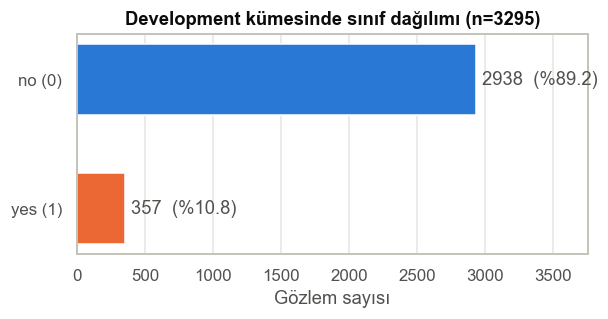

Her müşteriye 'no' diyen model  → accuracy = 0.892, sensitivity = 0.000
Sabit skor üreten (bilgisiz) model → AP = 0.108 (= pozitif oran)


In [8]:
counts = y_dev_label.value_counts().reindex(["no", "yes"])
fig, ax = plt.subplots(figsize=(6, 2.6))
bars = ax.barh([f"{k} ({int(k == 'yes')})" for k in counts.index], counts.values,
               color=[CLASS_COLORS[k] for k in counts.index], height=0.55)
for b, n in zip(bars, counts.values):
    ax.text(b.get_width() + 40, b.get_y() + b.get_height() / 2, f"{n}  (%{100 * n / len(y_dev):.1f})",
            va="center", color=C_INK)
ax.set_xlim(0, counts.max() * 1.28)
ax.invert_yaxis()
ax.set_xlabel("Gözlem sayısı")
ax.set_title(f"Development kümesinde sınıf dağılımı (n={len(y_dev)})")
ax.grid(axis="y", visible=False)
savefig(fig, "eda_class_distribution")
plt.show()

pos_rate = y_dev.mean()
print(f"Her müşteriye 'no' diyen model  → accuracy = {1 - pos_rate:.3f}, sensitivity = 0.000")
print(f"Sabit skor üreten (bilgisiz) model → AP = {average_precision_score(y_dev, np.zeros(len(y_dev))):.3f} (= pozitif oran)")

**Yorum:** Pozitif sınıf (abone olan müşteri) development verisinin yaklaşık %11'idir. Bu dengesizlik nedeniyle accuracy yanıltıcıdır: hiçbir şey öğrenmeyen çoğunluk sınıfı modeli bile ~%89 accuracy alır ama tek bir aboneyi yakalayamaz. Bu yüzden:

- **Birincil metrik AP**'dir: Precision–Recall eğrisinin özetidir, eşikten bağımsızdır ve bilgisiz bir modelde pozitif oranına (~0.11) eşittir — yani taban çizgisi açıkça bellidir.
- Eşiğe bağlı metriklerden **Sensitivity, Specificity, F1 ve Balanced Accuracy** birlikte raporlanır; 0.50 eşiğinde dengesiz veride sensitivity'nin düşük kalması beklenir.
- Tüm bölmeler (dev/test, outer ve inner CV, %15 early-stop alt kümesi) stratified yapılır; aksi hâlde küçük alt kümelerde pozitif sayısı çok oynar.

## 6. Sayısal özellikler

Ortalama, medyan, SD, IQR, min–maks ve çarpıklık. `pdays` için 999 kodu dağılımı bozduğundan ek olarak 999 hariç tutularak da özetlenir.

In [9]:
def describe_numeric(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({"ortalama": s.mean(), "medyan": s.median(), "SD": s.std(), "Q1": q1, "Q3": q3,
                      "IQR": q3 - q1, "min": s.min(), "maks": s.max(), "çarpıklık": s.skew()})


num_summary = X_dev[NUM_COLS].apply(describe_numeric).T
num_summary.loc["pdays (999 hariç)"] = describe_numeric(X_dev.pdays[X_dev.pdays != 999])
num_summary.to_csv(RES_DIR / "eda_numeric_summary.csv")
num_summary.round(3)

,ortalama,medyan,SD,Q1,Q3,IQR,min,maks,çarpıklık
age,40.181,38.000,10.397,32.000,47.000,15.000,18.000,88.000,0.699
campaign,2.551,2.000,2.608,1.000,3.000,2.000,1.000,35.000,4.176
pdays,959.211,999.000,194.802,999.000,999.000,0.000,1.000,999.000,-4.693
previous,0.189,0.000,0.545,0.000,0.000,0.000,0.000,6.000,3.983
emp.var.rate,0.083,1.100,1.568,-1.800,1.400,3.200,-3.400,1.400,-0.728
cons.price.idx,93.585,93.876,0.582,93.075,93.994,0.919,92.201,94.767,-0.234
cons.conf.idx,-40.494,-41.800,4.582,-42.700,-36.400,6.300,-50.800,-26.900,0.290
euribor3m,3.619,4.857,1.737,1.334,4.961,3.627,0.635,5.045,-0.709
nr.employed,5166.247,5191.000,73.622,5099.100,5228.100,129.000,4963.600,5228.100,-1.068
pdays (999 hariç),5.788,4.000,3.907,3.000,6.000,3.000,1.000,21.000,1.684


kaydedildi: figures/eda_numeric_hist.png


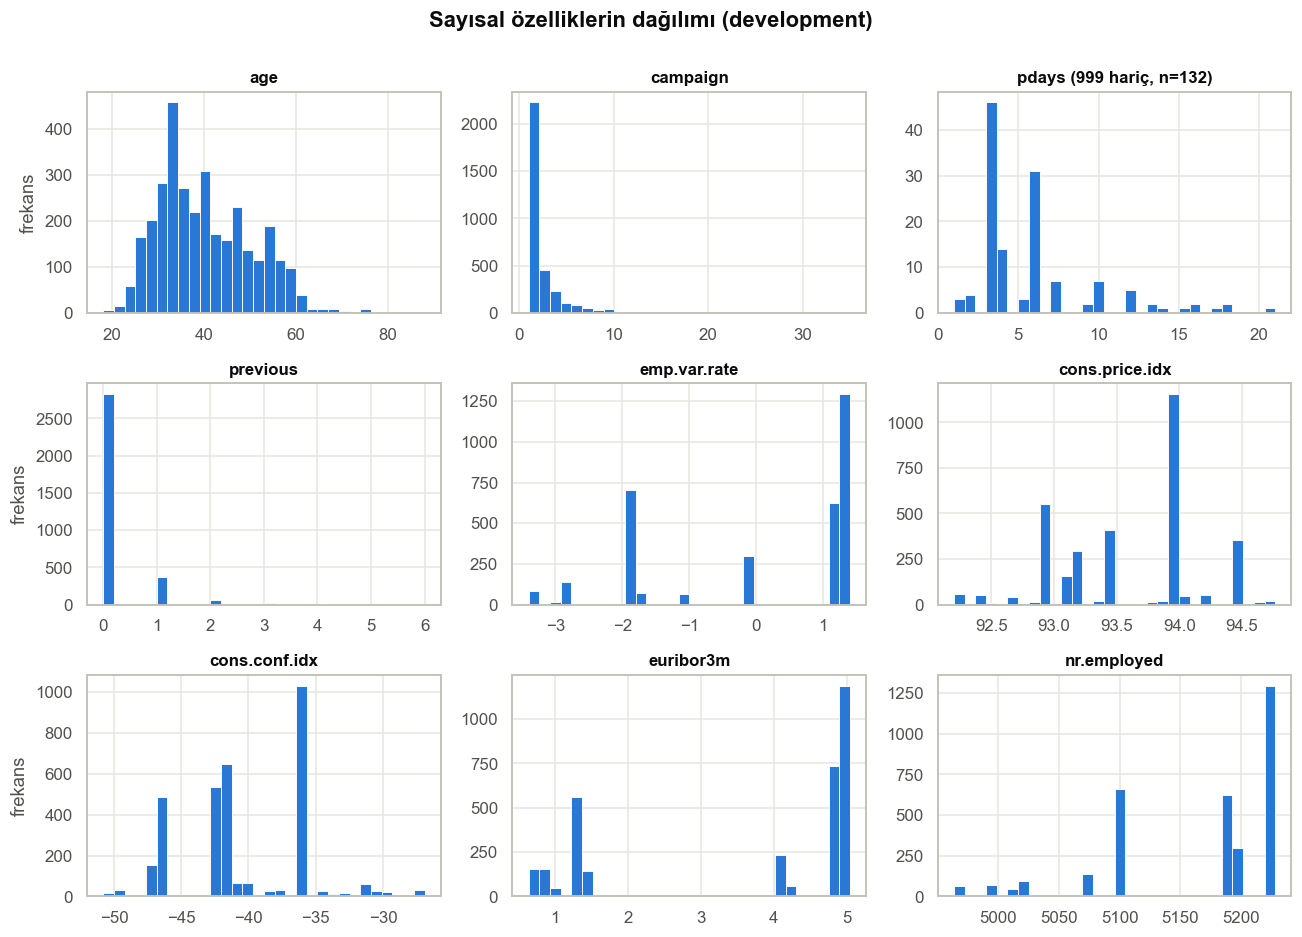

In [10]:
def numeric_values(col):
    s = X_dev[col]
    if col == "pdays":
        s = s[s != 999]
        return s, f"pdays (999 hariç, n={len(s)})"
    return s, col


fig, axes = plt.subplots(3, 3, figsize=(12, 8.5))
for i, (ax, col) in enumerate(zip(axes.flat, NUM_COLS)):
    s, title = numeric_values(col)
    ax.hist(s, bins=30, color=C_NO, edgecolor="white", linewidth=0.6)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel("frekans" if i % 3 == 0 else "")
fig.suptitle("Sayısal özelliklerin dağılımı (development)", fontweight="bold", y=1.0)
fig.tight_layout()
savefig(fig, "eda_numeric_hist")
plt.show()

kaydedildi: figures/eda_numeric_boxplot.png


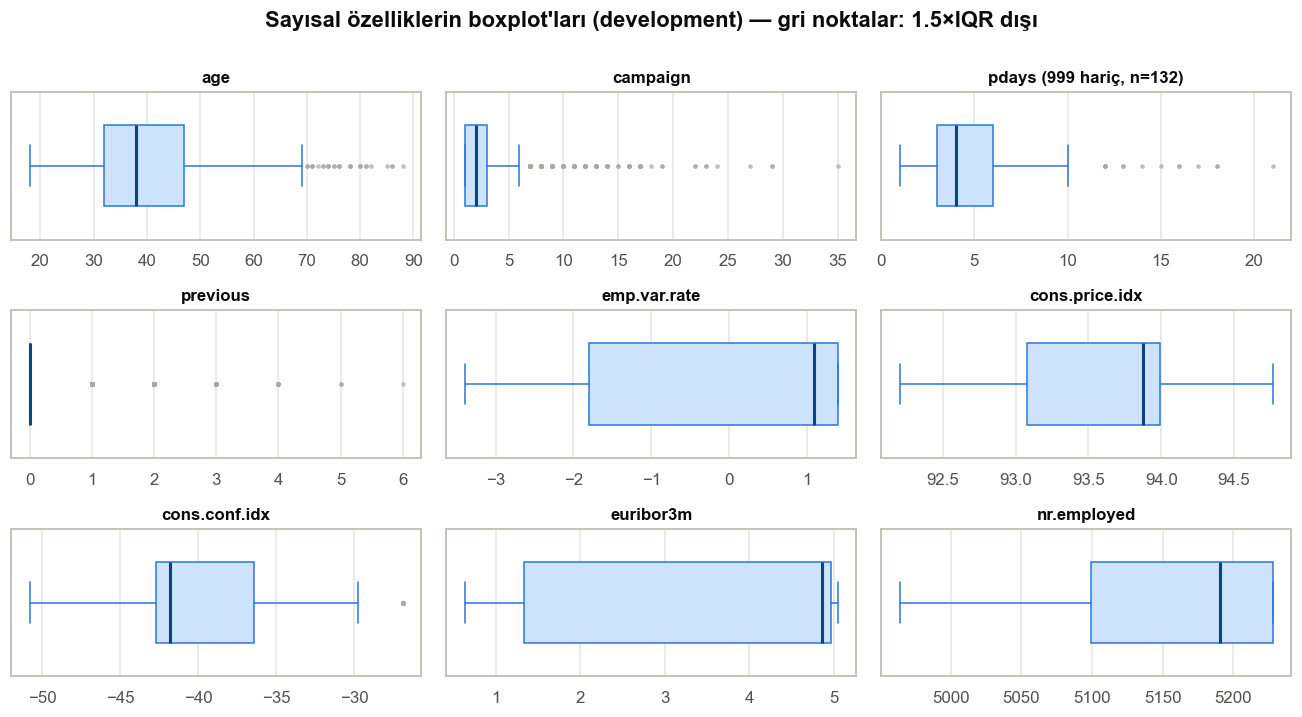

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(12, 6.5))
for ax, col in zip(axes.flat, NUM_COLS):
    s, title = numeric_values(col)
    ax.boxplot(s, orientation="horizontal", widths=0.55, patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", edgecolor=C_NO),
               medianprops=dict(color="#104281", linewidth=2),
               whiskerprops=dict(color=C_NO), capprops=dict(color=C_NO),
               flierprops=dict(marker="o", markersize=3, markerfacecolor=C_MUTED, markeredgecolor="none", alpha=0.7))
    ax.set_title(title, fontsize=11)
    ax.set_yticks([])
fig.suptitle("Sayısal özelliklerin boxplot'ları (development) — gri noktalar: 1.5×IQR dışı", fontweight="bold", y=1.0)
fig.tight_layout()
savefig(fig, "eda_numeric_boxplot")
plt.show()

## 7. Kategorik özellikler ve `"unknown"` kodları

Tam frekans tablosu `results/eda_categorical_freq.csv` dosyasına yazılır. Grafiklerde `"unknown"` kategorisi gri gösterilir.

In [12]:
freq = pd.concat({c: X_dev[c].value_counts().rename("n").to_frame() for c in CAT_COLS},
                 names=["özellik", "kategori"])
freq["yüzde"] = 100 * freq["n"] / len(X_dev)
freq.to_csv(RES_DIR / "eda_categorical_freq.csv")
freq.round(1)

n  yüzde
özellik     kategori                        
job         admin.                804   24.4
            blue-collar           718   21.8
            technician            547   16.6
            services              318    9.7
            management            265    8.0
            retired               135    4.1
            self-employed         122    3.7
            entrepreneur          111    3.4
            housemaid              95    2.9
            unemployed             83    2.5
            student                62    1.9
            unknown                35    1.1
marital     married              2027   61.5
            single                908   27.6
            divorced              352   10.7
            unknown                 8    0.2
education   university.degree    1008   30.6
            high.school           736   22.3
            basic.9y              463   14.1
            professional.course   418   12.7
            basic.4y              362   11.0
            basic.6y              179    5.4
            unknown               128    3.9
            illiterate              1    0.0
default     no                   2656   80.6
            unknown               638   19.4
            yes                     1    0.0
housing     yes                  1749   53.1
            no                   1456   44.2
            unknown                90    2.7
loan        no                   2679   81.3
            yes                   526   16.0
            unknown                90    2.7
contact     cellular             2102   63.8
            telephone            1193   36.2
month       may                  1127   34.2
            jul                   568   17.2
            aug                   495   15.0
            jun                   439   13.3
            nov                   340   10.3
            apr                   166    5.0
            oct                    56    1.7
            sep                    52    1.6
            mar                    35    1.1
            dec                    17    0.5
day_of_week tue                   700   21.2
            mon                   684   20.8
            thu                   677   20.5
            wed                   630   19.1
            fri                   604   18.3
poutcome    nonexistent          2828   85.8
            failure               350   10.6
            success               117    3.6

kaydedildi: figures/eda_categorical_bars.png


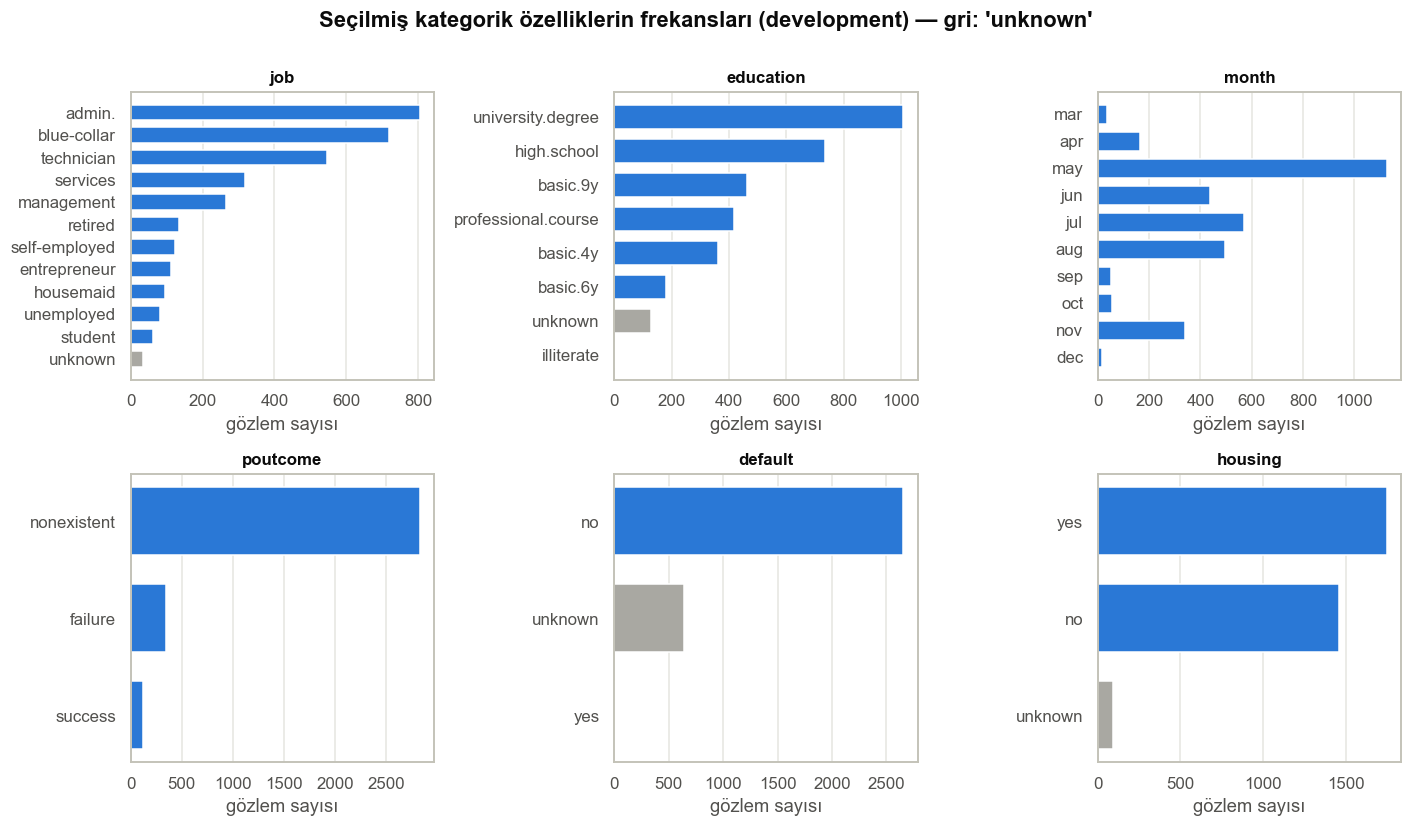

In [13]:
SHOW_CAT = ["job", "education", "month", "poutcome", "default", "housing"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for ax, col in zip(axes.flat, SHOW_CAT):
    vc = X_dev[col].value_counts()
    if col == "month":
        vc = vc.reindex([m for m in MONTH_ORDER if m in vc.index])
    ax.barh(vc.index, vc.values, height=0.7, color=[C_MUTED if k == "unknown" else C_NO for k in vc.index])
    ax.invert_yaxis()
    ax.set_title(col, fontsize=11)
    ax.set_xlabel("gözlem sayısı")
    ax.grid(axis="y", visible=False)
fig.suptitle("Seçilmiş kategorik özelliklerin frekansları (development) — gri: 'unknown'", fontweight="bold", y=1.0)
fig.tight_layout()
savefig(fig, "eda_categorical_bars")
plt.show()

In [14]:
unk = X_dev[CAT_COLS] == "unknown"
unk_summary = pd.DataFrame({"unknown (n)": unk.sum(), "unknown (%)": 100 * unk.mean()}).query("`unknown (n)` > 0")
print("housing ve loan sütunlarında 'unknown' aynı satırlarda mı?", bool((unk.housing == unk.loan).all()))
print(f"En az bir 'unknown' içeren satır: {unk.any(axis=1).sum()} (%{100 * unk.any(axis=1).mean():.1f})")
print("default dağılımı:", X_dev.default.value_counts().to_dict())
unk_summary.round(2)

housing ve loan sütunlarında 'unknown' aynı satırlarda mı? True
En az bir 'unknown' içeren satır: 820 (%24.9)
default dağılımı: {'no': 2656, 'unknown': 638, 'yes': 1}


,unknown (n),unknown (%)
job,35,1.06
marital,8,0.24
education,128,3.88
default,638,19.36
housing,90,2.73
loan,90,2.73


### 7.1 Önceki temas bilgisinin tutarlılığı (`pdays`, `previous`, `poutcome`)

Veri sözlüğüne göre `pdays = 999` "müşteriyle önceden temas kurulmamış" anlamına gelir. Bu tanım `previous` (önceki temas sayısı) ve `poutcome` (önceki kampanya sonucu) ile çapraz kontrol edilir.

In [15]:
consistency = pd.crosstab([X_dev.pdays.ne(999).rename("pdays≠999"), X_dev.previous.gt(0).rename("previous>0")],
                          X_dev.poutcome)
consistency.to_csv(RES_DIR / "eda_prior_contact_consistency.csv")
n_conflict = ((X_dev.pdays == 999) & (X_dev.previous > 0)).sum()
print(f"pdays = 999 olduğu hâlde previous > 0 olan satır: {n_conflict} (hepsinde poutcome = 'failure')")
consistency

pdays = 999 olduğu hâlde previous > 0 olan satır: 335 (hepsinde poutcome = 'failure')


poutcome              failure  nonexistent  success
pdays≠999 previous>0                               
False     False             0         2828        0
          True            335            0        0
True      True             15            0      117

**Bulgu:** `pdays = 999` olan satırların bir kısmında önceki temas sayısı sıfırdan büyüktür ve önceki kampanya sonucu `failure` olarak kayıtlıdır. Dolayısıyla 999 kodu bu veri setinde "önceden temas yok"tan çok **"son temas tarihi kayıtlı değil"** anlamını taşır. Önceki temasın varlığı bilgisi `previous` ve `poutcome` sütunlarında ayrıca mevcuttur; bu nedenle `pdays` için oluşturulacak gösterge sütunu tarafsız biçimde **"pdays = 999"** olarak adlandırılır.

## 8. Korelasyon matrisi (sayısal özellikler)

Pearson korelasyonu; `pdays` ham hâliyle (999 dahil) alınmıştır, bu nedenle `pdays` ile kurduğu ilişkiler pratikte "önceden temas edildi mi?" bilgisini yansıtır.

kaydedildi: figures/eda_correlation.png


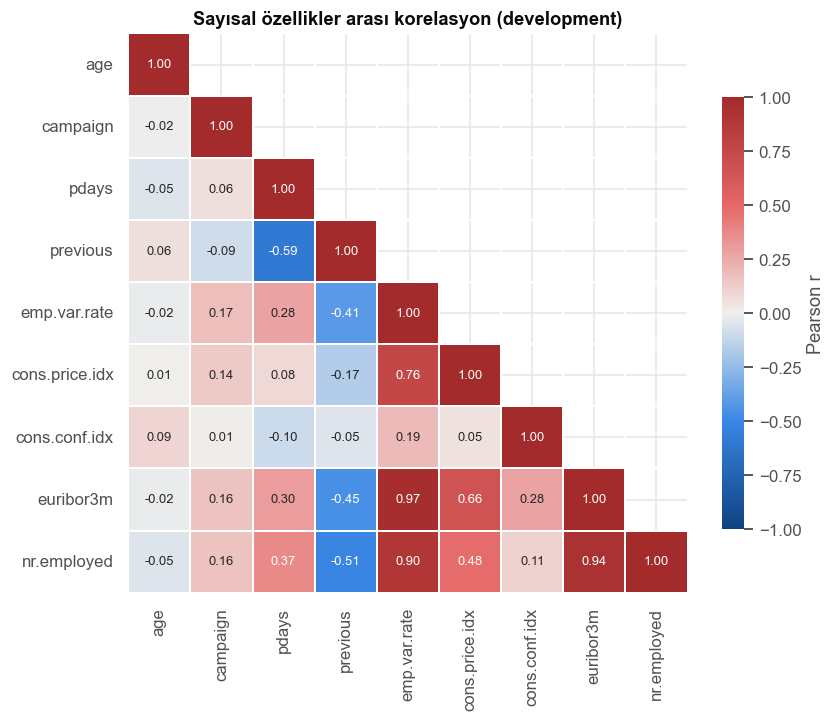

|r| ≥ 0.70 olan çiftler:
emp.var.rate  euribor3m         0.970
euribor3m     nr.employed       0.942
emp.var.rate  nr.employed       0.897
              cons.price.idx    0.760


In [16]:
corr = X_dev[NUM_COLS].corr(method="pearson")
fig, ax = plt.subplots(figsize=(8.2, 6.8))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cmap=DIVERGING, vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8.5}, linewidths=1, linecolor="white", square=True,
            cbar_kws={"shrink": 0.75, "label": "Pearson r"}, ax=ax)
ax.set_title("Sayısal özellikler arası korelasyon (development)")
savefig(fig, "eda_correlation")
plt.show()

pairs = corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1)).stack()
print("|r| ≥ 0.70 olan çiftler:")
print(pairs[pairs.abs() >= 0.70].sort_values(key=abs, ascending=False).round(3).to_string())

## 9. Seçilmiş özelliklerin hedefe göre betimsel karşılaştırması

> **Uyarı:** Bu bölüm yalnızca betimseldir. Burada gözlenen hedef–özellik ilişkilerine dayanarak **özellik eleme, özellik seçimi veya ön işleme stratejisi seçimi yapılmaz** (yönerge Bölüm 4). Tüm özellikler modele girer; ön işleme alternatifleri yalnızca inner CV içinde karşılaştırılır.

kaydedildi: figures/eda_target_numeric.png


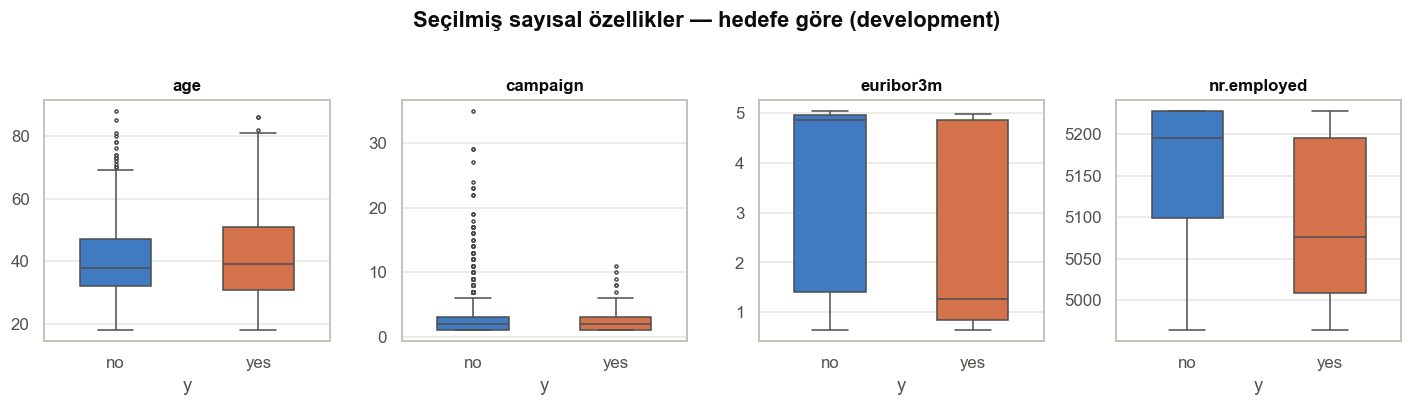

y                         no       yes
age         mean      39.983    41.812
            median    38.000    39.000
campaign    mean       2.616     2.008
            median     2.000     2.000
euribor3m   mean       3.797     2.152
            median     4.857     1.260
nr.employed mean    5175.057  5093.743
            median  5195.800  5076.200

In [17]:
SEL_NUM = ["age", "campaign", "euribor3m", "nr.employed"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, col in zip(axes, SEL_NUM):
    sns.boxplot(x=y_dev_label, y=X_dev[col], hue=y_dev_label, order=["no", "yes"], palette=CLASS_COLORS,
                width=0.5, linewidth=1, fliersize=2, legend=False, ax=ax)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel("y")
    ax.set_ylabel("")
fig.suptitle("Seçilmiş sayısal özellikler — hedefe göre (development)", fontweight="bold", y=1.02)
fig.tight_layout()
savefig(fig, "eda_target_numeric")
plt.show()

X_dev[SEL_NUM].groupby(y_dev_label).agg(["mean", "median"]).T.round(3)

kaydedildi: figures/eda_target_categorical.png


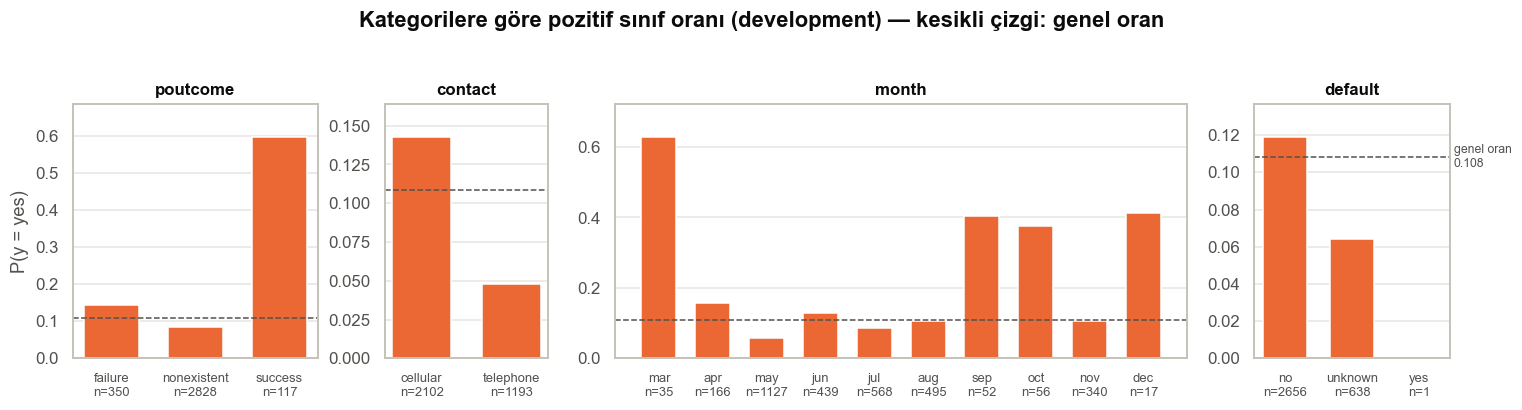

P(yes | pdays≠999, son temas tarihi kayıtlı) = 0.576  (n=132)
P(yes | pdays=999)                          = 0.089  (n=3163)


In [18]:
SEL_CAT = ["poutcome", "contact", "month", "default"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), gridspec_kw={"width_ratios": [3, 2, 7, 2.4]})
for ax, col in zip(axes, SEL_CAT):
    rate = y_dev.groupby(X_dev[col]).agg(["mean", "size"])
    if col == "month":
        rate = rate.reindex([m for m in MONTH_ORDER if m in rate.index])
    ax.bar([f"{k}\nn={n}" for k, n in rate["size"].items()], rate["mean"], color=C_YES, width=0.65)
    ax.axhline(pos_rate, color=C_INK, linestyle="--", linewidth=1)
    ax.set_title(col, fontsize=11)
    ax.set_ylim(0, min(1, rate["mean"].max() * 1.15))
    ax.tick_params(axis="x", labelsize=8.5)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("P(y = yes)")
axes[-1].text(1.02, pos_rate, f"genel oran\n{pos_rate:.3f}", transform=axes[-1].get_yaxis_transform(),
              va="center", fontsize=8, color=C_INK)
fig.suptitle("Kategorilere göre pozitif sınıf oranı (development) — kesikli çizgi: genel oran", fontweight="bold", y=1.03)
fig.tight_layout()
savefig(fig, "eda_target_categorical")
plt.show()

contacted = X_dev.pdays != 999
print(f"P(yes | pdays≠999, son temas tarihi kayıtlı) = {y_dev[contacted].mean():.3f}  (n={contacted.sum()})")
print(f"P(yes | pdays=999)                          = {y_dev[~contacted].mean():.3f}  (n={(~contacted).sum()})")

## 10. Aykırı değerlerin işaretlenmesi

İki yöntem yan yana: **IQR kuralı** (Q1 − 1.5·IQR, Q3 + 1.5·IQR dışı) ve **yüzdelik kuralı** (%1–%99 dışı). Değerler yalnızca işaretlenir, **hiçbir satır silinmez**. `pdays` için 999 bir aykırı değer değil özel kod olduğundan hesaba 999 hariç değerler alınır.

In [19]:
rows = []
for col in NUM_COLS:
    s, _ = numeric_values(col)
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    p1, p99 = s.quantile([0.01, 0.99])
    out_iqr, out_pct = (s < lo) | (s > hi), (s < p1) | (s > p99)
    rows.append({"özellik": "pdays (999 hariç)" if col == "pdays" else col, "IQR": iqr,
                 "alt çit": lo, "üst çit": hi, "IQR dışı (n)": out_iqr.sum(), "IQR dışı (%)": 100 * out_iqr.mean(),
                 "P1": p1, "P99": p99, "P1–P99 dışı (n)": out_pct.sum(), "P1–P99 dışı (%)": 100 * out_pct.mean()})
outliers = pd.DataFrame(rows).set_index("özellik")
outliers.to_csv(RES_DIR / "eda_outliers.csv")
outliers.round(2)

,IQR,alt çit,üst çit,IQR dışı (n),IQR dışı (%),P1,P99,P1–P99 dışı (n),P1–P99 dışı (%)
özellik,,,,,,,,,
age,15.00,9.50,69.50,29,0.88,23.00,68.00,52,1.58
campaign,2.00,-2.00,6.00,187,5.68,1.00,14.00,28,0.85
pdays (999 hariç),3.00,-1.50,10.50,15,11.36,1.00,18.00,1,0.76
previous,0.00,0.00,0.00,467,14.17,0.00,3.00,15,0.46
emp.var.rate,3.20,-6.60,6.20,0,0.00,-3.40,1.40,0,0.00
cons.price.idx,0.92,91.70,95.37,0,0.00,92.20,94.60,19,0.58
cons.conf.idx,6.30,-52.15,-26.95,34,1.03,-50.00,-26.90,19,0.58
euribor3m,3.63,-4.11,10.40,0,0.00,0.68,4.97,49,1.49
nr.employed,129.00,4905.60,5421.60,0,0.00,4963.60,5228.10,0,0.00


### `pdays = 999` neden özel işlem gerektiriyor?

Aşağıdaki hücre yalnızca **gösterim** amaçlıdır (model eğitiminde kullanılmaz): `pdays` ham hâliyle RobustScaler'a verilirse ne olacağını gösterir.

In [20]:
rs = RobustScaler().fit(X_dev[["pdays"]])
z = rs.transform(X_dev.loc[X_dev.pdays != 999, ["pdays"]]).ravel()
print(f"RobustScaler öğrenilen parametreler: medyan = {rs.center_[0]:.0f}, ölçek (IQR) = {rs.scale_[0]:.0f}  "
      "(IQR = 0 olduğu için sklearn ölçeği 1'e çeker)")
print(f"pdays≠999 olan {len(z)} müşterinin ölçeklenmiş pdays değeri: {z.min():.0f} … {z.max():.0f}")

RobustScaler öğrenilen parametreler: medyan = 999, ölçek (IQR) = 1  (IQR = 0 olduğu için sklearn ölçeği 1'e çeker)
pdays≠999 olan 132 müşterinin ölçeklenmiş pdays değeri: -998 … -978


## 11. EDA'dan çıkan ön işleme kararları

Aşağıdaki kararlar hedef–özellik ilişkilerine değil, **veri sözlüğüne ve veri kalitesi bulgularına** dayanır. Öğrenilen tüm parametreler (medyan, kategori sözlüğü, ölçekleyici istatistikleri, kırpma eşikleri) `02_nested_cv.ipynb` içinde yalnızca ilgili eğitim alt kümesinde (fit) öğrenilir.

| Konu | Karar | Gerekçe |
|---|---|---|
| `duration` | Tüm modellerden çıkarılır | Görüşme bitmeden bilinmez (önceden sabitlenmiş kural) |
| Kopya satırlar | Silinmez; dev/test bölmesi grup-farkında | Farklı görüşmeler; test ↔ development ikiz sızıntısını önler |
| `"unknown"` | Ana deneylerde ayrı kategori olarak tutulur | Gerçek NaN değil; eksikliğin kendisi bilgi taşıyabilir. Kat-içi en sık sınıf imputasyonu ek karşılaştırma olarak değerlendirilir |
| `pdays = 999` | NaN'a çevrilir → kat-içi medyan imputasyonu + "pdays = 999" göstergesi (0/1) | 999 bir gün sayısı değildir; ham hâli RobustScaler'da ~−990 değerleri üretir. Kod, "önceden temas yok"tan çok "son temas tarihi kayıtlı değil" anlamındadır (Bölüm 7.1); bilgi göstergede korunur, satır silinmez |
| Kategorik kodlama | `OneHotEncoder(handle_unknown="ignore")` | Kat içinde görülmeyen nadir kategoriler (ör. `default = yes`) hata vermeden sıfır vektöre düşer |
| Ölçekleme | Standard / MinMax / Robust (M4 ve otomatik aramada karşılaştırılır) | Çarpık dağılımlı ve farklı ölçekli özellikler |
| Aykırı değerler | Silme yok; isteğe bağlı kat-içi P1–P99 kırpma (otomatik arama seçeneği) | Aykırı değerler gerçek gözlemler; IQR kuralı sıfır-yığılmalı özelliklerde (`previous`) dejenere olur |

## 12. Test edilebilir deney hipotezleri

Aşağıdaki hipotezler EDA bulgularından türetilmiş ve **nested CV başlamadan önce** yazılmıştır. Her biri hangi karşılaştırmayla sınanacağını belirtir. Optimizer ve scheduler'a ilişkin (M2, M3, M6) teorik beklentiler ayrıca `configs/manual_candidates.json` içinde kayıtlıdır.

| # | EDA bulgusu | Hipotez | Nasıl sınanacak |
|---|---|---|---|
| H1 | `campaign` sağa çok çarpık (çarpıklık ≈ 4.2, P99 = 14, maks = 35); `previous` sıfır-yığılmalı | MinMax ölçekleme değerlerin çoğunu dar bir aralığa sıkıştırdığı için StandardScaler'dan daha iyi sonuç vermez (ΔAP ≤ 0) | M1 (Standard) vs M4 (MinMax): iç CV mean AP, her outer katta ve tam development iç CV'de |
| H2 | Aykırı değerler az ve gerçek gözlemler: P1–P99 dışı oran her özellikte < %1.6 | Kat-içi P1–P99 kırpma AP'yi anlamlı biçimde artırmaz (fark iç CV SD'si düzeyinde kalır) | Ek analiz A2: M1 vs M1 + kırpma, tam development iç CV (ana seçim bütçesi dışında) |
| H3 | Hedefle en güçlü ayrışan sinyaller tek-özellik/monoton ilişkiler (ör. `euribor3m` medyanı no: 4.86, yes: 1.26; `poutcome = success` grubunda pozitif oran ≈ 0.60); makro göstergeler birbiriyle \|r\| ≥ 0.90 korelasyonlu | Sinyal büyük ölçüde doğrusal olduğundan MLP'nin Logistic Regression'a üstünlüğü sınırlı kalır: outer CV mean AP farkı (MLP − LR) outer SD düzeyini aşmaz | Outer CV Mean ± SD AP: manuel/otomatik MLP vs LR |
| H4 | Development'ta yalnızca 357 pozitif; her inner-fit alt kümesinde ≈ 135 pozitif, ~63 girdi boyutu | Daha büyük mimari (64,32) — ≈ 6.1 bin parametre — (32,)'ye göre AP artışı sağlamaz ve en iyi epoch'a daha erken ulaşır (daha hızlı aşırı öğrenme) | M1 vs M5: iç CV mean AP ve ortalama en iyi epoch |
| H5 | `default` sütununun %19.4'ü `"unknown"`; bu grupta pozitif oran (≈ 0.064) `no` grubundan (≈ 0.119) farklı → eksiklik rastgele değil, bilgi taşıyor olabilir | `"unknown"`u ayrı kategori olarak tutmak, kat-içi en sık sınıfla doldurmaya göre AP'yi düşürmez | Ek analiz A1: M1 vs M1 + en sık sınıf imputasyonu, tam development iç CV |
| H6 | Pozitif oran %10.8 | 0.50 eşiğinde sensitivity düşük (< 0.50), specificity yüksek (> 0.90) kalır; bu nedenle AP ve Balanced Accuracy ana yorum metrikleridir | Outer CV ve bağımsız test eşik-bağımlı metrikleri |

> A1 ve A2, yönergenin "unknown için ayrı kategori veya kat-içi imputation seçenekleri değerlendirilecektir" ve "aykırı değer yönetimi" maddelerini kontrollü (tek faktörlü) biçimde sınamak için eklenen **ek analizlerdir**; ana arama bütçesine (6 manuel + 6 otomatik) ve nihai model seçimine dahil edilmezler.

## Bu notebook'un çıktıları

| Dosya | İçerik |
|---|---|
| `results/data_dictionary.csv` | Veri sözlüğü ve özellik rolleri |
| `results/dataset_split.csv` | Orijinal satır indeksi, küme (development/test), hedef, kopya grubu |
| `results/dataset_split_summary.csv` | Kümelerin boyutu ve sınıf oranları |
| `results/eda_feature_profile.csv` | Tablo 1 — özellik profili, unknown ve özel kodlar |
| `results/eda_numeric_summary.csv` | Sayısal betimsel istatistikler |
| `results/eda_categorical_freq.csv` | Kategorik frekans tabloları |
| `results/eda_outliers.csv` | IQR ve P1–P99 aykırı değer işaretleme |
| `results/eda_prior_contact_consistency.csv` | `pdays` / `previous` / `poutcome` tutarlılık tablosu |
| `figures/eda_*.png` | Sınıf dağılımı, histogram, boxplot, kategorik frekanslar, korelasyon, hedefe göre karşılaştırmalar |